In [1]:
import numpy as np
import matplotlib.pyplot as plt 

import pandas as pd  
import seaborn as sns 
from sklearn import metrics
import scipy.io as sio
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
import warnings
warnings.filterwarnings('ignore')
import xarray as xr
from sklearn.preprocessing import PolynomialFeatures

In [2]:
## training data

week = '2'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [3]:
from skgarden import RandomForestQuantileRegressor

In [4]:
def get_tercile_predictions_single_grid(observed_data_train, model_output_train, observed_data_test, model_output_test,
                                       mss, ne):
    '''
    Generate tercile probability predictions for observed test data based on a fitted quantile regression model for a single grid point.

    Parameters:
    observed_data_train (np.ndarray): 1D array containing the observed training data for a single grid point.
    model_output_train (np.ndarray): 1D array of model output for training for a single grid point.
    observed_data_test (np.ndarray): 1D array containing the observed testing data for a single grid point.
    model_output_test (np.ndarray): 1D array of model output for testing for a single grid point.

    Returns:
    np.ndarray: A 2D array of shape (number of test data points, 3), where each element contains the probabilities of falling into the lower, middle, and upper terciles.
    '''
    
    quantiles = np.linspace(0, 100, 40)
    
    ts_grid_ij_obs_train = observed_data_train
    ts_grid_ij_model_train = model_output_train
    ts_grid_ij_obs_test = observed_data_test
    ts_grid_ij_model_test = model_output_test

    if np.all(np.isnan(ts_grid_ij_obs_train)):
        return np.zeros((ts_grid_ij_obs_test.shape[0], 3))  # Return zeros if training data is all NaNs

    X_train = ts_grid_ij_model_train.reshape(-1, 1)
    y_train = ts_grid_ij_obs_train
    X_test = ts_grid_ij_model_test.reshape(-1, 1)
    y_test = ts_grid_ij_obs_test

    # Train the model
    rfqr = RandomForestQuantileRegressor(random_state=0, min_samples_split=mss, n_estimators=ne)
    rfqr.fit(X_train, y_train)

    # Predict quantiles for test data
    pred_test_quantiles = [rfqr.predict(X_test, quantile=q).reshape(-1, 1) for q in quantiles]
    q_preds_test = np.concatenate(pred_test_quantiles, axis=1)
    
    # Construct reference CDF
    reference_cdf = np.interp(np.linspace(np.min(ts_grid_ij_obs_train), np.max(ts_grid_ij_obs_train), y_test.shape[0]), 
                              np.quantile(y_train, np.linspace(0, 100, y_train.shape[0]) / 100), 
                              np.linspace(0, 100, y_train.shape[0]) / 100, left=0, right=1)

    # Calculate individual CDFs for each test point
    individual_cdfs = np.zeros((y_test.shape[0], y_test.shape[0]))
    for k in range(y_test.shape[0]):
        xp_k = q_preds_test[k, :]
        cdf_k = np.interp(np.linspace(np.min(xp_k), np.max(xp_k), y_test.shape[0]), 
                          xp_k, np.linspace(0, 100, 40) / 100, left=0, right=1)
        individual_cdfs[k, :] = cdf_k  # CDF for each point

    p1, p2 = 0.333, 0.667

    # Calculate the absolute difference from the specific value
    absolute_difference_from_value_1 = np.abs(reference_cdf - p1)
    absolute_difference_from_value_2 = np.abs(reference_cdf - p2)

    # Find the index of the minimum difference
    index_of_value_p33_ref = np.argmin(absolute_difference_from_value_1)
    index_of_value_p67_ref = np.argmin(absolute_difference_from_value_2)

    # Obtain the tercile predictions
    triplet_array = np.zeros((y_test.shape[0], 3))
    for k in range(y_test.shape[0]):
        # Take the correct individual CDF
        p_bn = individual_cdfs[k, :][index_of_value_p33_ref]
        p_n = individual_cdfs[k, :][index_of_value_p67_ref] - p_bn
        p_an = 1 - p_n - p_bn

        triplet_array[k, 0], triplet_array[k, 1], triplet_array[k, 2] = p_bn, p_n, p_an

    return triplet_array

In [5]:
mss = 50
ne = 22
tp = get_tercile_predictions_single_grid(data_obs_train['prcp'].values[:,13,15], 
                                    data_model_train.mean('M')['prcp'].values[:,13,15], 
                                    data_obs_test['prcp'].values[:,13,15], 
                                    data_model_test.mean('M')['prcp'].values[:,13,15], mss, ne)

In [6]:
tp

array([[0.2804417 , 0.14200383, 0.57755447],
       [0.18457448, 0.27550674, 0.53991878],
       [0.22822543, 0.37419686, 0.39757771],
       [0.19120872, 0.36667217, 0.44211911],
       [0.30489612, 0.36997182, 0.32513206],
       [0.10895162, 0.29211003, 0.59893835],
       [0.11723327, 0.28994568, 0.59282105],
       [0.12977861, 0.22678361, 0.64343778],
       [0.13955835, 0.34987057, 0.51057108],
       [0.30489612, 0.36997182, 0.32513206],
       [0.12429808, 0.32703606, 0.54866586],
       [0.11061695, 0.29504809, 0.59433497],
       [0.10384115, 0.2648223 , 0.63133655],
       [0.11723327, 0.28994568, 0.59282105],
       [0.15784245, 0.13762305, 0.7045345 ],
       [0.14955586, 0.37687558, 0.47356856],
       [0.30700017, 0.17164679, 0.52135304],
       [0.30700017, 0.17164679, 0.52135304],
       [0.26297228, 0.13888748, 0.59814025],
       [0.12516886, 0.23368518, 0.64114597],
       [0.30489612, 0.36997182, 0.32513206],
       [0.20593095, 0.37487607, 0.41919298],
       [0.

In [7]:
def rps_clim(class_value):
    
    if len(class_value.shape)>1:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_clim_probs = np.cumsum(np.ones((class_value.shape[0],3))*0.3333, axis=1).round(3)
        values = ((cum_clim_probs-cum_obs)**2)/(class_value.shape[1]-1)
    else:
        cum_obs = np.cumsum(class_value, axis=0)
        cum_clim_probs = np.cumsum(np.ones(3)*0.3333, axis=0).round(3)
        values = ((cum_clim_probs-cum_obs)**2)/(class_value.shape[0]-1)
    
    
    if len(class_value.shape)>1:
        return np.mean(np.sum(values, axis=1))
    else:
        return np.sum(values)

In [8]:
def rps_forecast(class_value, probs, grid_point=None):
    """
    grid_point: optional if only a single point is being fed as an input
    """
    if grid_point is not None:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_fc_probs = np.cumsum(probs[grid_point[0], grid_point[1]], axis=1).round(3)
        values = ((cum_fc_probs-cum_obs)**2)/(class_value.shape[1]-1)
    else:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_fc_probs = np.cumsum(probs, axis=1).round(3)
        values = ((cum_fc_probs-cum_obs)**2)/(class_value.shape[1]-1)
        
    
    if len(class_value.shape)>1:
        return np.mean(np.sum(values, axis=1))
    else:
        return np.sum(values)

In [9]:
def make_ohe(array):
    p_33 = np.quantile(array, q=1/3)
    p_67 = np.quantile(array, q=2/3)
    
    ohe = np.zeros((array.shape[0],3))
    for i in range(len(array)):
        if array[i]<=p_33:
            ohe[i][0] = 1
        elif p_33<array[i]<=p_67:
            ohe[i][1] = 1
        elif array[i]>p_67:
            ohe[i][2] = 1
    
    return ohe, p_33, p_67

In [10]:
ohe,_,_ = make_ohe(data_obs_test['prcp'].values[:,14,16])
rps_c = rps_clim(ohe)
rps_fc = rps_forecast(ohe, tp)

In [11]:
1-(rps_fc/rps_c)

0.10539846956325671

In [12]:
data_obs_train['prcp'].values.shape

(386, 32, 31)

In [13]:
import time

In [14]:
# mss = list(range(40,56))
# ne = list(range(20,31))
# ohe,_,_ = make_ohe(data_obs_test['prcp'].values[:,13,15])
# rps_c = rps_clim(ohe)
# max_rpss = -np.inf

# start = time.time()

# for ms in mss:
#     for n in ne:
#         tp = get_tercile_predictions_single_grid(data_obs_train['prcp'].values[:,13,15], 
#                                     data_model_train.mean('M')['prcp'].values[:,13,15], 
#                                     data_obs_test['prcp'].values[:,13,15], 
#                                     data_model_test.mean('M')['prcp'].values[:,13,15], ms, n)
#         rps_fc = rps_forecast(ohe, tp)
#         rpss = 1-(rps_fc/rps_c)
        
#         if rpss>max_rpss:
#             max_rpss = rpss
#             best_params = {'mss':ms, 'ne':n}
        
#         print(f'At grid point 13,15, for n_estimators: {n}, min_samples_split: {ms}, the rpss is {rpss}')
#         print('-'*60)
# end = time.time()

# print(f"Time elapsed: {end-start}")

In [15]:
# max_rpss

In [16]:
# best_params

In [17]:
# tp = get_tercile_predictions_single_grid(data_obs_train['prcp'].values[:,14,16], 
#                                     data_model_train.mean('M')['prcp'].values[:,14,16], 
#                                     data_obs_test['prcp'].values[:,14,16], 
#                                     data_model_test.mean('M')['prcp'].values[:,14,16], 44, 20)

In [18]:
# ohe,_,_ = make_ohe(data_obs_test['prcp'].values[:,14,16])
# rps_c = rps_clim(ohe)
# rps_fc = rps_forecast(ohe, tp)

In [19]:
# 1-(rps_fc/rps_c)

In [20]:
# mss = list(range(55,61))
# ne = list(range(20,36))
# ohe,_,_ = make_ohe(data_obs_test['prcp'].values[:,14,16])
# rps_c = rps_clim(ohe)
# max_rpss = -np.inf

# for ms in mss:
#     for n in ne:
#         tp = get_tercile_predictions_single_grid(data_obs_train['prcp'].values[:,14,16], 
#                                     data_model_train.mean('M')['prcp'].values[:,14,16], 
#                                     data_obs_test['prcp'].values[:,14,16], 
#                                     data_model_test.mean('M')['prcp'].values[:,14,16], ms, n)
#         rps_fc = rps_forecast(ohe, tp)
#         rpss = 1-(rps_fc/rps_c)
        
#         if rpss>max_rpss:
#             max_rpss = rpss
#             best_params = {'mss':ms, 'ne':n}
        
#         print(f'At grid point 14,16, for n_estimators: {n}, min_samples_split: {ms}, the rpss is {rpss}')
#         print('-'*115)

In [10]:
import time

In [11]:
mss = list(range(40, 56))
ne = list(range(20, 36))
params_d = {}

for i in range(32):
    for j in range(31):
        if np.all(np.isnan(data_obs_train['prcp'].values[:, i, j])):
            print(f"Skipping {i, j} as null...")
            continue
        print(f'Grid point: {i, j}')
        max_rpss = -np.inf
        ohe, _, _ = make_ohe(data_obs_test['prcp'].values[:, i, j])
        rps_c = rps_clim(ohe)
        
        best_params_ij = {'mss': None, 'ne': None, 'b_rpss': max_rpss}  # Initialize best_params_ij with default values
        s = time.time()
        
        for ms in mss:
            for n in ne:
                tp = get_tercile_predictions_single_grid(
                    data_obs_train['prcp'].values[:, i, j], 
                    data_model_train.mean('M')['prcp'].values[:, i, j], 
                    data_obs_test['prcp'].values[:, i, j], 
                    data_model_test.mean('M')['prcp'].values[:, i, j], ms, n
                )
                rps_fc = rps_forecast(ohe, tp)
                rpss = 1 - (rps_fc / rps_c)
                
                if rpss > max_rpss:
                    max_rpss = rpss
                    best_params_ij = {'mss': ms, 'ne': n, 'b_rpss': max_rpss}
                    print(f"New best params for grid point ({i},{j}): {best_params_ij}")
                    print(f'At grid point {i},{j}, for n_estimators: {n}, min_samples_split: {ms}, the rpss is {rpss}')
                    print('-' * 115)

        if max_rpss > -np.inf:  # Ensure only grid points with valid RPSS are added
            params_d[(i, j)] = best_params_ij
            print(f"Final best params for grid point ({i},{j}): {best_params_ij}")

        e = time.time()
        print(f'Time elapsed: {e - s} seconds')
        if (i, j) in params_d:
            print(params_d.get((i, j), 0))
        print('-' * 115)

Skipping (0, 0) as null...
Skipping (0, 1) as null...
Skipping (0, 2) as null...
Skipping (0, 3) as null...
Skipping (0, 4) as null...
Skipping (0, 5) as null...
Skipping (0, 6) as null...
Skipping (0, 7) as null...
Skipping (0, 8) as null...
Skipping (0, 9) as null...
Skipping (0, 10) as null...
Skipping (0, 11) as null...
Skipping (0, 12) as null...
Skipping (0, 13) as null...
Skipping (0, 14) as null...
Skipping (0, 15) as null...
Skipping (0, 16) as null...
Skipping (0, 17) as null...
Skipping (0, 18) as null...
Skipping (0, 19) as null...
Skipping (0, 20) as null...
Skipping (0, 21) as null...
Skipping (0, 22) as null...
Skipping (0, 23) as null...
Skipping (0, 24) as null...
Skipping (0, 25) as null...
Skipping (0, 26) as null...
Skipping (0, 27) as null...
Skipping (0, 28) as null...
Skipping (0, 29) as null...
Skipping (0, 30) as null...
Skipping (1, 0) as null...
Skipping (1, 1) as null...
Skipping (1, 2) as null...
Skipping (1, 3) as null...
Skipping (1, 4) as null...
Skippin

New best params for grid point (2,9): {'mss': 50, 'ne': 34, 'b_rpss': -0.027328644187549767}
At grid point 2,9, for n_estimators: 34, min_samples_split: 50, the rpss is -0.027328644187549767
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (2,9): {'mss': 51, 'ne': 30, 'b_rpss': -0.025274321754275464}
At grid point 2,9, for n_estimators: 30, min_samples_split: 51, the rpss is -0.025274321754275464
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (2,9): {'mss': 52, 'ne': 30, 'b_rpss': -0.023255534637565356}
At grid point 2,9, for n_estimators: 30, min_samples_split: 52, the rpss is -0.023255534637565356
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (2,9): {'mss': 52, 'ne': 34, 'b_rpss': -0.022117

New best params for grid point (2,10): {'mss': 53, 'ne': 29, 'b_rpss': 0.05014320132528782}
At grid point 2,10, for n_estimators: 29, min_samples_split: 53, the rpss is 0.05014320132528782
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (2,10): {'mss': 54, 'ne': 29, 'b_rpss': 0.05172943732699942}
At grid point 2,10, for n_estimators: 29, min_samples_split: 54, the rpss is 0.05172943732699942
-------------------------------------------------------------------------------------------------------------------
Final best params for grid point (2,10): {'mss': 54, 'ne': 29, 'b_rpss': 0.05172943732699942}
Time elapsed: 110.27043414115906 seconds
{'mss': 54, 'ne': 29, 'b_rpss': 0.05172943732699942}
-------------------------------------------------------------------------------------------------------------------
Skipping (2, 11) as null...
Skipping (2, 12) as null...
Skipping (2, 13) as null...
Sk

New best params for grid point (3,10): {'mss': 41, 'ne': 25, 'b_rpss': 0.05716633154466377}
At grid point 3,10, for n_estimators: 25, min_samples_split: 41, the rpss is 0.05716633154466377
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (3,10): {'mss': 42, 'ne': 21, 'b_rpss': 0.05752916330103397}
At grid point 3,10, for n_estimators: 21, min_samples_split: 42, the rpss is 0.05752916330103397
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (3,10): {'mss': 42, 'ne': 25, 'b_rpss': 0.05852934073740501}
At grid point 3,10, for n_estimators: 25, min_samples_split: 42, the rpss is 0.05852934073740501
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (3,10): {'mss': 43, 'ne': 25, 'b_rpss': 0.059302117770

New best params for grid point (3,11): {'mss': 44, 'ne': 27, 'b_rpss': 0.037492609486888706}
At grid point 3,11, for n_estimators: 27, min_samples_split: 44, the rpss is 0.037492609486888706
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (3,11): {'mss': 44, 'ne': 29, 'b_rpss': 0.03885081444575478}
At grid point 3,11, for n_estimators: 29, min_samples_split: 44, the rpss is 0.03885081444575478
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (3,11): {'mss': 44, 'ne': 30, 'b_rpss': 0.04079108436683099}
At grid point 3,11, for n_estimators: 30, min_samples_split: 44, the rpss is 0.04079108436683099
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (3,11): {'mss': 46, 'ne': 29, 'b_rpss': 0.0431003835

New best params for grid point (4,8): {'mss': 40, 'ne': 34, 'b_rpss': 0.1413709714096838}
At grid point 4,8, for n_estimators: 34, min_samples_split: 40, the rpss is 0.1413709714096838
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (4,8): {'mss': 41, 'ne': 34, 'b_rpss': 0.14140373628471292}
At grid point 4,8, for n_estimators: 34, min_samples_split: 41, the rpss is 0.14140373628471292
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (4,8): {'mss': 44, 'ne': 32, 'b_rpss': 0.14333702405255688}
At grid point 4,8, for n_estimators: 32, min_samples_split: 44, the rpss is 0.14333702405255688
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (4,8): {'mss': 49, 'ne': 26, 'b_rpss': 0.14463009961418805}
At

... (250 outputs left out)

New best params for grid point (29,11): {'mss': 40, 'ne': 22, 'b_rpss': -0.06105652486134461}
At grid point 29,11, for n_estimators: 22, min_samples_split: 40, the rpss is -0.06105652486134461
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (29,11): {'mss': 40, 'ne': 23, 'b_rpss': -0.06006082284287029}
At grid point 29,11, for n_estimators: 23, min_samples_split: 40, the rpss is -0.06006082284287029
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (29,11): {'mss': 40, 'ne': 24, 'b_rpss': -0.059888885792170665}
At grid point 29,11, for n_estimators: 24, min_samples_split: 40, the rpss is -0.059888885792170665
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (29,11): {'mss': 40, 'ne': 25, 'b_rpss':

New best params for grid point (29,12): {'mss': 43, 'ne': 32, 'b_rpss': -0.10259039486318478}
At grid point 29,12, for n_estimators: 32, min_samples_split: 43, the rpss is -0.10259039486318478
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (29,12): {'mss': 44, 'ne': 28, 'b_rpss': -0.09932325960222221}
At grid point 29,12, for n_estimators: 28, min_samples_split: 44, the rpss is -0.09932325960222221
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (29,12): {'mss': 44, 'ne': 29, 'b_rpss': -0.09844909722039841}
At grid point 29,12, for n_estimators: 29, min_samples_split: 44, the rpss is -0.09844909722039841
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (29,12): {'mss': 44, 'ne': 30, 'b_rpss': -

New best params for grid point (30,6): {'mss': 42, 'ne': 31, 'b_rpss': -0.14996835611287485}
At grid point 30,6, for n_estimators: 31, min_samples_split: 42, the rpss is -0.14996835611287485
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (30,6): {'mss': 44, 'ne': 31, 'b_rpss': -0.14608834473644916}
At grid point 30,6, for n_estimators: 31, min_samples_split: 44, the rpss is -0.14608834473644916
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (30,6): {'mss': 46, 'ne': 31, 'b_rpss': -0.14581001945394445}
At grid point 30,6, for n_estimators: 31, min_samples_split: 46, the rpss is -0.14581001945394445
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (30,6): {'mss': 47, 'ne': 20, 'b_rpss': -0.14128

New best params for grid point (30,7): {'mss': 40, 'ne': 26, 'b_rpss': -0.1206020922118245}
At grid point 30,7, for n_estimators: 26, min_samples_split: 40, the rpss is -0.1206020922118245
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (30,7): {'mss': 40, 'ne': 31, 'b_rpss': -0.12014048540697941}
At grid point 30,7, for n_estimators: 31, min_samples_split: 40, the rpss is -0.12014048540697941
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (30,7): {'mss': 40, 'ne': 32, 'b_rpss': -0.11930128183365407}
At grid point 30,7, for n_estimators: 32, min_samples_split: 40, the rpss is -0.11930128183365407
-------------------------------------------------------------------------------------------------------------------
New best params for grid point (30,7): {'mss': 40, 'ne': 33, 'b_rpss': -0.0971953

In [12]:
rpss = np.zeros((32,31))

In [13]:
for i in params_d:
    rpss[i[0],i[1]] = params_d[i]['b_rpss']

In [14]:
import matplotlib.pyplot as plt

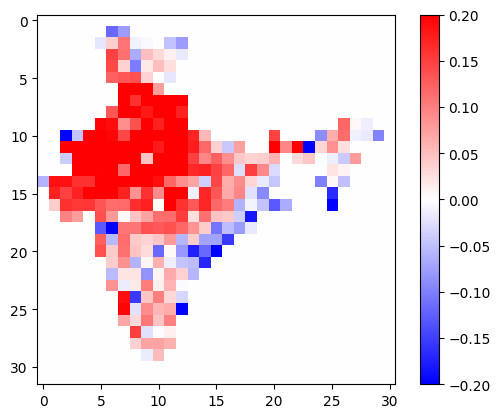

In [15]:
plt.imshow(np.flip(rpss, axis=0), cmap='bwr', vmin=-0.2, vmax=0.2)
plt.colorbar()

In [16]:
np.nanmin(rpss)

-0.9282956822888611

In [17]:
np.nanmax(rpss)

0.33815841462189267

In [18]:
import json

In [19]:
params_d1 = {str(k):v for k,v in params_d.items()}

In [20]:
with open('best_params_2.json', 'w') as json_file:
    json.dump(params_d1, json_file)

In [22]:
import ast

# Read dictionary from a JSON file
with open('best_params_2.json', 'r') as json_file:
    params_str_keys = json.load(json_file)

# Convert string keys back to tuples
best_params_prop = {ast.literal_eval(k): v for k, v in params_str_keys.items()}

In [23]:
len(best_params_prop)

316

## For RPSS < 0

In [24]:
indices = np.argwhere(rpss<0)

In [25]:
indices.shape

(79, 2)

In [26]:
indices[:,0].shape

(79,)

In [27]:
for i in indices:
    print(i)

[2 9]
[4 9]
[ 4 10]
[6 8]
[ 6 12]
[7 8]
[ 7 12]
[8 7]
[ 8 12]
[9 6]
[9 9]
[ 9 13]
[10  8]
[10 11]
[10 12]
[10 13]
[10 14]
[11 10]
[11 12]
[11 13]
[11 14]
[11 15]
[12  6]
[12 12]
[12 14]
[12 15]
[12 16]
[13  5]
[13  6]
[13 15]
[13 16]
[13 17]
[13 18]
[14 17]
[14 18]
[15 17]
[15 18]
[15 19]
[15 20]
[15 21]
[15 25]
[16 13]
[16 18]
[16 19]
[16 25]
[17  0]
[17 14]
[17 19]
[17 20]
[17 24]
[17 26]
[18 17]
[18 20]
[19  2]
[19 24]
[19 25]
[19 26]
[20 16]
[20 23]
[20 27]
[21  2]
[21  3]
[21 24]
[21 27]
[21 28]
[21 29]
[22 28]
[26 10]
[26 11]
[27  8]
[28  8]
[28 12]
[29  5]
[29  8]
[29  9]
[29 11]
[29 12]
[30  6]
[30  7]


In [28]:
mss = list(range(56, 81))
ne = list(range(36, 61))
extreme_params_d = {}

for i in indices:
    if np.all(np.isnan(data_obs_train['prcp'].values[:, i[0], i[1]])):
        print(f"Skipping {i[0], i[1]} as null...")
        continue
    print(f'Grid point: {i[0], i[1]}')
    max_rpss = -np.inf
    ohe, _, _ = make_ohe(data_obs_test['prcp'].values[:, i[0], i[1]])
    rps_c = rps_clim(ohe)

    best_params_ij = {'mss': None, 'ne': None, 'b_rpss': max_rpss}  # Initialize best_params_ij with default values
    s = time.time()

    for ms in mss:
        for n in ne:
            tp = get_tercile_predictions_single_grid(
                data_obs_train['prcp'].values[:, i[0], i[1]], 
                data_model_train.mean('M')['prcp'].values[:, i[0], i[1]], 
                data_obs_test['prcp'].values[:, i[0], i[1]], 
                data_model_test.mean('M')['prcp'].values[:, i[0], i[1]], ms, n
            )
            rps_fc = rps_forecast(ohe, tp)
            rpss = 1 - (rps_fc / rps_c)

            if rpss > max_rpss:
                max_rpss = rpss
                best_params_ij = {'mss': ms, 'ne': n, 'b_rpss': max_rpss}
                print(f"New best params for grid point ({i},{j}): {best_params_ij}")
                print(f'At grid point {i[0]},{i[1]}, for n_estimators: {n}, min_samples_split: {ms}, the rpss is {rpss}')
                print('-' * 115)

    if max_rpss > -np.inf:  # Ensure only grid points with valid RPSS are added
        extreme_params_d[(i[0], i[1])] = best_params_ij
        print(f"Final best params for grid point ({i[0]},{i[1]}): {best_params_ij}")

    e = time.time()
    print(f'Time elapsed: {e - s} seconds')
    if (i[0], i[1]) in extreme_params_d:
        print(extreme_params_d.get((i[0], i[1]), 0))
    print('-' * 115)

Grid point: (2, 9)
New best params for grid point ([2 9],30): {'mss': 56, 'ne': 36, 'b_rpss': -0.013298631818248863}
At grid point 2,9, for n_estimators: 36, min_samples_split: 56, the rpss is -0.013298631818248863
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([2 9],30): {'mss': 56, 'ne': 37, 'b_rpss': -0.010111262853727432}
At grid point 2,9, for n_estimators: 37, min_samples_split: 56, the rpss is -0.010111262853727432
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([2 9],30): {'mss': 56, 'ne': 38, 'b_rpss': -0.008996184157173737}
At grid point 2,9, for n_estimators: 38, min_samples_split: 56, the rpss is -0.008996184157173737
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([2 9],30): {'

New best params for grid point ([2 9],30): {'mss': 72, 'ne': 51, 'b_rpss': 0.050266122528462076}
At grid point 2,9, for n_estimators: 51, min_samples_split: 72, the rpss is 0.050266122528462076
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([2 9],30): {'mss': 74, 'ne': 50, 'b_rpss': 0.05070319571231752}
At grid point 2,9, for n_estimators: 50, min_samples_split: 74, the rpss is 0.05070319571231752
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([2 9],30): {'mss': 74, 'ne': 51, 'b_rpss': 0.05121825762608079}
At grid point 2,9, for n_estimators: 51, min_samples_split: 74, the rpss is 0.05121825762608079
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([2 9],30): {'mss': 75, 'ne': 48, 'b_rpss':

New best params for grid point ([4 9],30): {'mss': 59, 'ne': 47, 'b_rpss': -0.017343988910547115}
At grid point 4,9, for n_estimators: 47, min_samples_split: 59, the rpss is -0.017343988910547115
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([4 9],30): {'mss': 59, 'ne': 55, 'b_rpss': -0.016686561532947675}
At grid point 4,9, for n_estimators: 55, min_samples_split: 59, the rpss is -0.016686561532947675
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([4 9],30): {'mss': 59, 'ne': 58, 'b_rpss': -0.016684463684155215}
At grid point 4,9, for n_estimators: 58, min_samples_split: 59, the rpss is -0.016684463684155215
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([4 9],30): {'mss': 59, 'ne': 59,

New best params for grid point ([4 9],30): {'mss': 77, 'ne': 57, 'b_rpss': 0.005510680452469163}
At grid point 4,9, for n_estimators: 57, min_samples_split: 77, the rpss is 0.005510680452469163
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([4 9],30): {'mss': 79, 'ne': 57, 'b_rpss': 0.005616245484820981}
At grid point 4,9, for n_estimators: 57, min_samples_split: 79, the rpss is 0.005616245484820981
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([4 9],30): {'mss': 80, 'ne': 47, 'b_rpss': 0.0059474013258404845}
At grid point 4,9, for n_estimators: 47, min_samples_split: 80, the rpss is 0.0059474013258404845
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([4 9],30): {'mss': 80, 'ne': 57, 'b_

New best params for grid point ([6 8],30): {'mss': 56, 'ne': 56, 'b_rpss': -0.015651921725578166}
At grid point 6,8, for n_estimators: 56, min_samples_split: 56, the rpss is -0.015651921725578166
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([6 8],30): {'mss': 56, 'ne': 57, 'b_rpss': -0.015588826120683574}
At grid point 6,8, for n_estimators: 57, min_samples_split: 56, the rpss is -0.015588826120683574
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([6 8],30): {'mss': 56, 'ne': 59, 'b_rpss': -0.015108418747273422}
At grid point 6,8, for n_estimators: 59, min_samples_split: 56, the rpss is -0.015108418747273422
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([6 8],30): {'mss': 57, 'ne': 59,

New best params for grid point ([ 6 12],30): {'mss': 56, 'ne': 51, 'b_rpss': -0.2034405841179714}
At grid point 6,12, for n_estimators: 51, min_samples_split: 56, the rpss is -0.2034405841179714
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([ 6 12],30): {'mss': 57, 'ne': 47, 'b_rpss': -0.20324426710771681}
At grid point 6,12, for n_estimators: 47, min_samples_split: 57, the rpss is -0.20324426710771681
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([ 6 12],30): {'mss': 57, 'ne': 48, 'b_rpss': -0.20308122742410406}
At grid point 6,12, for n_estimators: 48, min_samples_split: 57, the rpss is -0.20308122742410406
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([ 6 12],30): {'mss': 57, 'ne': 

... (87 outputs left out)

New best params for grid point ([29  9],30): {'mss': 66, 'ne': 53, 'b_rpss': 0.02379444845337153}
At grid point 29,9, for n_estimators: 53, min_samples_split: 66, the rpss is 0.02379444845337153
-------------------------------------------------------------------------------------------------------------------
Final best params for grid point (29,9): {'mss': 66, 'ne': 53, 'b_rpss': 0.02379444845337153}
Time elapsed: 369.00041794776917 seconds
{'mss': 66, 'ne': 53, 'b_rpss': 0.02379444845337153}
-------------------------------------------------------------------------------------------------------------------
Grid point: (29, 11)
New best params for grid point ([29 11],30): {'mss': 56, 'ne': 36, 'b_rpss': -0.062410214110401485}
At grid point 29,11, for n_estimators: 36, min_samples_split: 56, the rpss is -0.062410214110401485
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([29 11],30): {'m

New best params for grid point ([29 12],30): {'mss': 58, 'ne': 36, 'b_rpss': -0.08015125970215031}
At grid point 29,12, for n_estimators: 36, min_samples_split: 58, the rpss is -0.08015125970215031
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([29 12],30): {'mss': 58, 'ne': 40, 'b_rpss': -0.07909581756210105}
At grid point 29,12, for n_estimators: 40, min_samples_split: 58, the rpss is -0.07909581756210105
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([29 12],30): {'mss': 59, 'ne': 40, 'b_rpss': -0.07877646412230188}
At grid point 29,12, for n_estimators: 40, min_samples_split: 59, the rpss is -0.07877646412230188
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([29 12],30): {'mss': 64, '

New best params for grid point ([30  6],30): {'mss': 59, 'ne': 48, 'b_rpss': -0.12091284607298736}
At grid point 30,6, for n_estimators: 48, min_samples_split: 59, the rpss is -0.12091284607298736
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([30  6],30): {'mss': 60, 'ne': 45, 'b_rpss': -0.12027146483653106}
At grid point 30,6, for n_estimators: 45, min_samples_split: 60, the rpss is -0.12027146483653106
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([30  6],30): {'mss': 62, 'ne': 45, 'b_rpss': -0.11932053079738103}
At grid point 30,6, for n_estimators: 45, min_samples_split: 62, the rpss is -0.11932053079738103
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([30  6],30): {'mss': 62, 'ne'

New best params for grid point ([30  7],30): {'mss': 64, 'ne': 42, 'b_rpss': -0.07042970028626794}
At grid point 30,7, for n_estimators: 42, min_samples_split: 64, the rpss is -0.07042970028626794
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([30  7],30): {'mss': 65, 'ne': 42, 'b_rpss': -0.06966336092671743}
At grid point 30,7, for n_estimators: 42, min_samples_split: 65, the rpss is -0.06966336092671743
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([30  7],30): {'mss': 68, 'ne': 59, 'b_rpss': -0.06867903746213444}
At grid point 30,7, for n_estimators: 59, min_samples_split: 68, the rpss is -0.06867903746213444
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([30  7],30): {'mss': 72, 'ne'

In [29]:
rpss = np.zeros((32,31))
for i in params_d:
    rpss[i[0],i[1]] = params_d[i]['b_rpss']

In [30]:
extreme_values_tuned_rpss = rpss.copy()

In [31]:
for i in extreme_params_d:
    extreme_values_tuned_rpss[i[0],i[1]] = extreme_params_d[i[0],i[1]]['b_rpss']

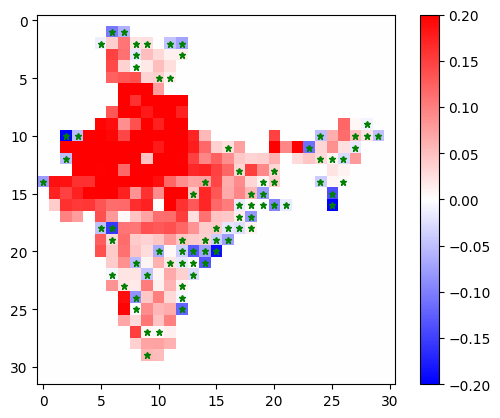

In [33]:
plt.imshow(np.flip(extreme_values_tuned_rpss, axis=0), cmap='bwr', vmin=-0.2, vmax=0.2)
for index in indices:
    plt.plot(index[1], 31-index[0], 'g*', markersize=5)
plt.colorbar()

In [34]:
np.argwhere(extreme_values_tuned_rpss<-0.9)

array([[15, 25]])

In [35]:
params_d2 = {str(k):v for k,v in extreme_params_d.items()}

In [36]:
with open('best_params_extr_2.json', 'w') as json_file:
    json.dump(params_d2, json_file)

In [84]:
import ast

# Read dictionary from a JSON file
with open('best_params_extr.json', 'r') as json_file:
    params_str_keys1 = json.load(json_file)

# Convert string keys back to tuples
best_params_prop1 = {ast.literal_eval(k): v for k, v in params_str_keys1.items()}

In [85]:
len(best_params_prop1)

69

In [88]:
np.nanmin(extreme_values_tuned_rpss)

-0.9282956822888611

In [89]:
np.nanmax(extreme_values_tuned_rpss)

0.38101518906582

In [95]:
np.argwhere(extreme_values_tuned_rpss<=-0.3)

array([[13,  6],
       [15, 25]])

(array([57., 42., 17., 10.,  6.,  3.,  2.,  1.,  0.,  2.]),
 array([ 0.       ,  2.5170975,  5.034195 ,  7.5512924, 10.06839  ,
        12.585487 , 15.102585 , 17.619682 , 20.13678  , 22.653877 ,
        25.170975 ], dtype=float32),
 <BarContainer object of 10 artists>)

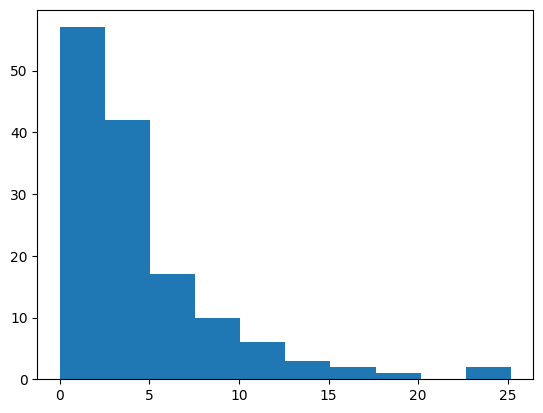

In [97]:
plt.hist(data_obs_test['prcp'].values[:,13,6])

(array([53., 17., 24.,  9., 10.,  9.,  7.,  6.,  1.,  4.]),
 array([ 0.      ,  1.34407 ,  2.68814 ,  4.03221 ,  5.37628 ,  6.72035 ,
         8.06442 ,  9.408489, 10.75256 , 12.09663 , 13.4407  ],
       dtype=float32),
 <BarContainer object of 10 artists>)

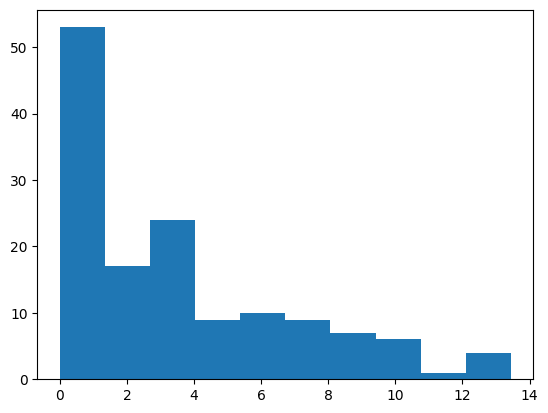

In [99]:
plt.hist(data_obs_test['prcp'].values[:,13,7])

In [107]:
params_d[(11,6)]

{'mss': 55, 'ne': 33, 'b_rpss': -0.011178555437335813}

In [106]:
extreme_params_d[(11,6)]

{'mss': 74, 'ne': 60, 'b_rpss': 0.013691009612951888}

In [108]:
extreme_params_d[(13,6)]

{'mss': 78, 'ne': 48, 'b_rpss': -0.3276302539902365}

In [109]:
params_d[(13,6)]

{'mss': 51, 'ne': 33, 'b_rpss': -0.3620909915490327}

In [123]:
new_indices = np.argwhere(extreme_values_tuned_rpss<-0.3)

In [125]:
new_indices

array([[13,  6],
       [15, 25]])

In [128]:
mss = list(range(10,21))
ne = list(range(100, 156))
extreme_params_d = {}

for i in new_indices:
    if np.all(np.isnan(data_obs_train['prcp'].values[:, i[0], i[1]])):
        print(f"Skipping {i[0], i[1]} as null...")
        continue
    print(f'Grid point: {i[0], i[1]}')
    max_rpss = -np.inf
    ohe, _, _ = make_ohe(data_obs_test['prcp'].values[:, i[0], i[1]])
    rps_c = rps_clim(ohe)

    best_params_ij = {'mss': None, 'ne': None, 'b_rpss': max_rpss}  # Initialize best_params_ij with default values
    s = time.time()

    for ms in mss:
        for n in ne:
            tp = get_tercile_predictions_single_grid(
                data_obs_train['prcp'].values[:, i[0], i[1]], 
                data_model_train.mean('M')['prcp'].values[:, i[0], i[1]], 
                data_obs_test['prcp'].values[:, i[0], i[1]], 
                data_model_test.mean('M')['prcp'].values[:, i[0], i[1]], ms, n
            )
            rps_fc = rps_forecast(ohe, tp)
            rpss = 1 - (rps_fc / rps_c)

            if rpss > max_rpss:
                max_rpss = rpss
                best_params_ij = {'mss': ms, 'ne': n, 'b_rpss': max_rpss}
                print(f"New best params for grid point ({i},{j}): {best_params_ij}")
                print(f'At grid point {i[0]},{i[1]}, for n_estimators: {n}, min_samples_split: {ms}, the rpss is {rpss}')
                print('-' * 115)

    if max_rpss > -np.inf:  # Ensure only grid points with valid RPSS are added
        extreme_params_d[(i[0], i[1])] = best_params_ij
        print(f"Final best params for grid point ({i[0]},{i[1]}): {best_params_ij}")

    e = time.time()
    print(f'Time elapsed: {e - s} seconds')
    if (i[0], i[1]) in extreme_params_d:
        print(extreme_params_d.get((i[0], i[1]), 0))
    print('-' * 115)

Grid point: (13, 6)
New best params for grid point ([13  6],11): {'mss': 10, 'ne': 100, 'b_rpss': -0.5230300559276879}
At grid point 13,6, for n_estimators: 100, min_samples_split: 10, the rpss is -0.5230300559276879
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([13  6],11): {'mss': 10, 'ne': 102, 'b_rpss': -0.5229330744598599}
At grid point 13,6, for n_estimators: 102, min_samples_split: 10, the rpss is -0.5229330744598599
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([13  6],11): {'mss': 10, 'ne': 104, 'b_rpss': -0.5227898122057006}
At grid point 13,6, for n_estimators: 104, min_samples_split: 10, the rpss is -0.5227898122057006
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([13  6],1

New best params for grid point ([13  6],11): {'mss': 12, 'ne': 139, 'b_rpss': -0.4599148017164567}
At grid point 13,6, for n_estimators: 139, min_samples_split: 12, the rpss is -0.4599148017164567
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([13  6],11): {'mss': 12, 'ne': 143, 'b_rpss': -0.45933949470989766}
At grid point 13,6, for n_estimators: 143, min_samples_split: 12, the rpss is -0.45933949470989766
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([13  6],11): {'mss': 12, 'ne': 144, 'b_rpss': -0.4591267632339029}
At grid point 13,6, for n_estimators: 144, min_samples_split: 12, the rpss is -0.4591267632339029
-------------------------------------------------------------------------------------------------------------------
New best params for grid point ([13  6],11): {'mss': 12, 'n

In [28]:
min_samples_to_split = np.zeros((32,31))
n_estimators = np.zeros((32,31))

for i in params_d:
    min_samples_to_split[i[0],i[1]] = params_d[i]['mss']
    n_estimators[i[0],i[1]] = params_d[i]['ne']

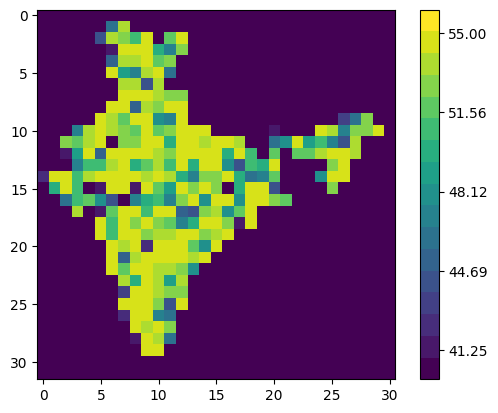

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

# Assuming min_samples_to_split is already defined and a numpy array
min_samples_to_split_flipped = np.flip(min_samples_to_split, axis=0)

# Create a discrete colormap with 50 levels
cmap = plt.get_cmap('viridis', 17)  # You can choose any colormap you like

# Plotting the image
plt.imshow(min_samples_to_split_flipped, cmap=cmap, vmin=40, vmax=56)
plt.colorbar(ticks=np.linspace(min_samples_to_split_flipped.min(), min_samples_to_split_flipped.max(), 17))
plt.show()

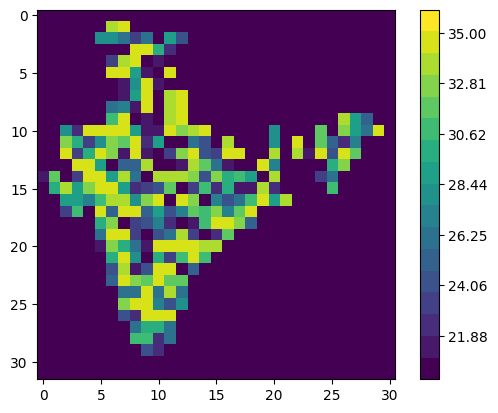

In [42]:
# Assuming min_samples_to_split is already defined and a numpy array
n_estimators_flipped = np.flip(n_estimators, axis=0)

# Create a discrete colormap with 50 levels
cmap = plt.get_cmap('viridis', 17)  # You can choose any colormap you like

# Plotting the image
plt.imshow(n_estimators_flipped, cmap=cmap, vmin=20, vmax=36)
plt.colorbar(ticks=np.linspace(n_estimators_flipped.min(), n_estimators_flipped.max(), 17))
plt.show()

In [26]:
np.save(f'./RPSS - Scores/tuned_rpss_{week}_IMD.npy', rpss)

In [27]:
np.nanmin(rpss)

-0.9282956822888611

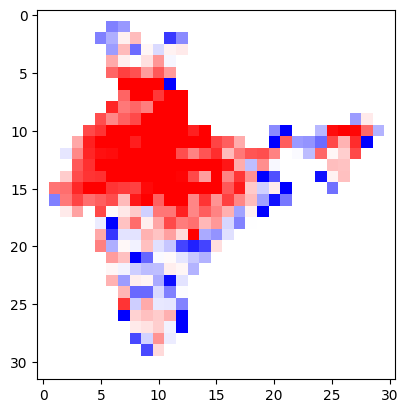

In [58]:
plt.imshow(np.flip(rpss, axis=0), vmin=-0.2, vmax=0.2, cmap='bwr')

In [111]:
data_obs_test['prcp'].values.shape

(140, 32, 31)

## Checking Hyperparameters 

In [1]:
import numpy as np

In [113]:
import ast
import json

# Read dictionary from a JSON file
with open('best_params_34_randomized.json', 'r') as json_file:
    params_str_keys = json.load(json_file)

# Convert string keys back to tuples
best_params_prop = {ast.literal_eval(k): v for k, v in params_str_keys.items()}

In [114]:
bp = list(best_params_prop.values())

In [115]:
bp

[{'mss': 65, 'ne': 25, 'b_rpss': -0.02249200798476525},
 {'mss': 61, 'ne': 29, 'b_rpss': 0.0591968742477168},
 {'mss': 70, 'ne': 45, 'b_rpss': 0.006052309473845052},
 {'mss': 70, 'ne': 40, 'b_rpss': -0.014928511766513441},
 {'mss': 69, 'ne': 25, 'b_rpss': 0.0056244202647126595},
 {'mss': 70, 'ne': 25, 'b_rpss': 0.051411166602109204},
 {'mss': 70, 'ne': 41, 'b_rpss': 0.09541687536848542},
 {'mss': 69, 'ne': 25, 'b_rpss': 0.020281912935966484},
 {'mss': 70, 'ne': 43, 'b_rpss': -0.038438615396076736},
 {'mss': 70, 'ne': 38, 'b_rpss': 0.019998547693033775},
 {'mss': 45, 'ne': 41, 'b_rpss': -0.2233363883318058},
 {'mss': 70, 'ne': 43, 'b_rpss': 0.13417753707789815},
 {'mss': 67, 'ne': 27, 'b_rpss': 0.04501799672177076},
 {'mss': 70, 'ne': 34, 'b_rpss': -0.02739356322629516},
 {'mss': 54, 'ne': 27, 'b_rpss': 0.06289133393894852},
 {'mss': 47, 'ne': 37, 'b_rpss': 0.022769930922726722},
 {'mss': 45, 'ne': 26, 'b_rpss': -0.006832496583751402},
 {'mss': 70, 'ne': 43, 'b_rpss': 0.2059175316566188

In [116]:
import pandas as pd

In [117]:
df = pd.DataFrame(bp)

In [118]:
df

,mss,ne,b_rpss
0,65,25,-0.022492
1,61,29,0.059197
2,70,45,0.006052
3,70,40,-0.014929
4,69,25,0.005624
...,...,...,...
318,46,44,0.034635
319,60,39,-0.076614
320,70,40,0.005316
321,70,43,-0.041152


In [119]:
df.min(axis=0)

mss       45.000000
ne        25.000000
b_rpss    -0.383203
dtype: float64

In [120]:
df.max(axis=0)

mss       70.000000
ne        45.000000
b_rpss     0.324376
dtype: float64

In [121]:
mss, ne = np.full((32,31), np.nan), np.full((32,31), np.nan)

In [122]:
for i in best_params_prop:
    mss[i] = best_params_prop[i]['mss']
    ne[i] = best_params_prop[i]['ne']

In [123]:
import matplotlib.pyplot as plt

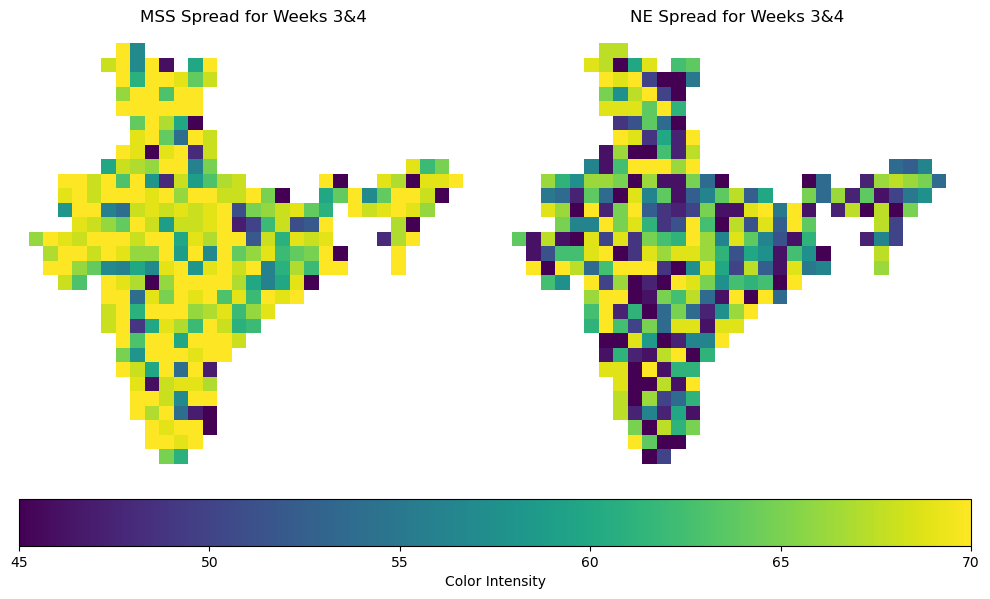

In [124]:
# Create a figure with GridSpec
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(10, 6))
gs = GridSpec(2, 2, height_ratios=[10, 1])  # Two rows, adjust height ratios

# Display the first matrix
ax1 = fig.add_subplot(gs[0, 0])
im1 = ax1.imshow(np.flip(mss, axis=0), cmap='viridis')
ax1.set_title('MSS Spread for Weeks 3&4')
ax1.axis('off')

# Display the second matrix
ax2 = fig.add_subplot(gs[0, 1])
im2 = ax2.imshow(np.flip(ne, axis=0), cmap='viridis')
ax2.set_title('NE Spread for Weeks 3&4')
ax2.axis('off')

# Add a colorbar below both images
cbar_ax = fig.add_subplot(gs[1, :])  # Span the colorbar across both columns
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Color Intensity')

# Save and display the plot
plt.tight_layout()
plt.savefig('MSS_NE_Week_34_fixed.jpg', dpi=400)
plt.show()